# Formative 3 (Group 16): Probability Distributions, Bayes' Theorem and Gradient Descent

| Member | Main work |
|---|---|
| Belyse Intwaza | Part 1 (EM algorithm), Part 3 iteration 2 |
| Erin Leyian | Part 2 (Bayes' theorem), Part 3 iteration 1 |
| Iza Prince Boaz | Part 4 (gradient descent in code), Part 3 iteration 3 |

| Section | Topic |
|---|---|
| **1** | Probability distributions: separating two groups of heights with the EM algorithm |
| **2** | Bayesian probability: which words predict a negative IMDb review? |
| **3** | Gradient descent by hand: handwritten, see [`Part3 Manual Calculation.pdf`](Part3%20Manual%20Calculation.pdf) (not in this notebook) |
| **4** | Gradient descent in code, with SciPy derivatives |

**Before running:** use Python 3.10 or newer, install the packages with `pip install -r requirements.txt`, and put `IMDB Dataset.csv` in this folder (needed for Section 2). Then choose **Run → Run All Cells**.

# 1. Probability Distributions: Finding Two Hidden Groups of Heights with EM

We have Galton's family heights (1886). We put **all the children's heights and all the fathers' heights into one pile**, then leave the labels out while fitting the model.

We assume each group's heights form a **bell curve** (a "hill"), described by 3 numbers:

| Number | Symbol | Meaning |
|---|---|---|
| mean | μ | where the middle of the hill is |
| variance | σ² | how wide the hill is (how varied the heights are) |
| share | π | what fraction of the pile belongs to this group |

**Goal:** find these 3 numbers for the child group and for the father group (6 numbers in total), using only the heights.

**How EM does it:** start with a guess, then repeat two steps until the log-likelihood improves by less than our chosen tolerance:
- **E-step:** give every person a percentage: how much child, how much father.
- **M-step:** use those percentages to recalculate each group's mean, variance, and share.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", "{:.4f}".format)

**Chart functions.** These only draw the charts (colours, labels, legends). None of the EM maths is in here.

In [2]:
CHILD_COLOR = "#2a78d6"    # blue
FATHER_COLOR = "#eb6834"   # orange
FEMALE_COLOR = "#1baf7a"   # green
MALE_COLOR = "#4a3aa7"     # purple
BAR_COLOR = "#dcdbd4"      # light gray

plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e1e0d9",
    "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "lines.linewidth": 2, "figure.dpi": 110,
})


def draw_histogram(ax, heights):
    """Plot the height distribution as a density histogram."""
    bins = np.arange(np.floor(heights.min()), np.ceil(heights.max()) + 1)
    ax.hist(heights, bins=bins, density=True, color=BAR_COLOR, edgecolor="white", label="Data")
    ax.set_xlabel("Height (inches)")


def plot_heights(heights):
    fig, ax = plt.subplots(figsize=(8, 3.4))
    draw_histogram(ax, heights)
    ax.set_title(f"What EM sees: {len(heights):,} heights, no labels")
    ax.set_ylabel("Density")
    return fig


def plot_fit(ax, heights, grid, child_curve, father_curve, title, lines=None):
    """Data + the two hills + their sum. `lines` = {label: x position} for vertical lines."""
    draw_histogram(ax, heights)
    ax.plot(grid, child_curve, color=CHILD_COLOR, label="Child hill")
    ax.plot(grid, father_curve, color=FATHER_COLOR, label="Father hill")
    ax.plot(grid, child_curve + father_curve, color="black", linewidth=1.5, label="Both added together")
    for (label, x), style in zip((lines or {}).items(), ["--", ":"]):
        ax.axvline(x, color="black", linestyle=style, linewidth=1.5, label=label)
    ax.set_title(title, fontsize=10)


def plot_log_likelihood(scores):
    fig, ax = plt.subplots(figsize=(8, 3.2))
    ax.plot(range(len(scores)), scores, color=CHILD_COLOR, marker="o", markersize=3)
    ax.set_title("Log-likelihood after each iteration (higher = better fit)")
    ax.set_xlabel("Iteration")
    ax.set_ylabel("Log-likelihood")
    return fig


def plot_child_probability(grid, p_child, boundary):
    fig, ax = plt.subplots(figsize=(8, 3.4))
    ax.plot(grid, p_child, color=CHILD_COLOR, label="P(Child | height)")
    ax.plot(grid, 1 - p_child, color=FATHER_COLOR, label="P(Father | height)")
    ax.axvline(boundary, color="black", linestyle=":", linewidth=1.5)
    ax.annotate(f"50/50 at {boundary:.2f} in", (boundary, 0.5), xytext=(6, 6), textcoords="offset points")
    ax.set_title("Probability of each group, for any height")
    ax.set_xlabel("Height (inches)")
    ax.set_ylabel("Probability")
    ax.legend(loc="center right", bbox_to_anchor=(1, 0.75))
    return fig


def plot_true_groups(heights, is_child, is_male):
    """The hidden labels, grouped two ways: by role and by sex."""
    bins = np.arange(np.floor(heights.min()), np.ceil(heights.max()) + 1)
    fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
    for ax, title, groups in [
        (left, "Grouped by role", [("Children", is_child, CHILD_COLOR), ("Fathers", ~is_child, FATHER_COLOR)]),
        (right, "Grouped by sex", [("Female", ~is_male, FEMALE_COLOR), ("Male", is_male, MALE_COLOR)]),
    ]:
        for name, mask, color in groups:
            ax.hist(heights[mask], bins=bins, density=True, histtype="step", linewidth=2,
                    color=color, label=f"{name} ({mask.sum()})")
        ax.set_title(f"{title} (each group scaled to the same size)", fontsize=10)
        ax.set_xlabel("Height (inches)")
        ax.legend(loc="upper right")
    left.set_ylabel("Density")
    return fig

## Step 1 — Load the data

The file repeats each father once for every one of his children, so we keep **each father only once** (one per family).

The labels (`is_child`, `is_male`) are the real labels. We keep them out of the fitting steps and compare them with the model results afterward.

934 children + 205 fathers = 1139 heights


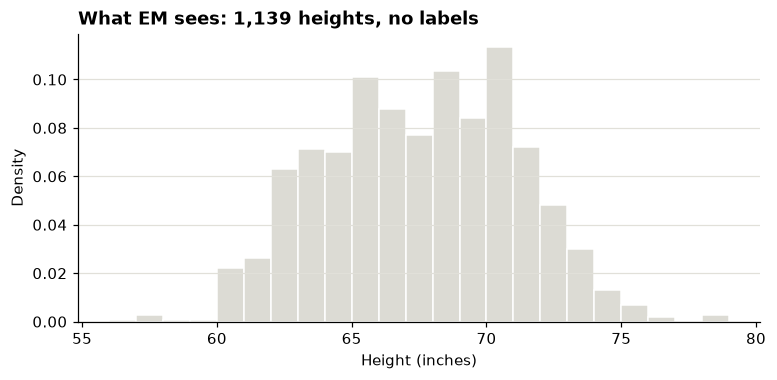

In [3]:
data = pd.read_csv("data/GaltonFamilies.csv")

children = data["childHeight"]
fathers = data.drop_duplicates("family")["father"]     # each father once

heights = np.concatenate([children, fathers])          # one pile, no labels

# Real labels, kept out of the EM fitting steps
is_child = np.concatenate([np.full(len(children), True), np.full(len(fathers), False)])
is_male = np.concatenate([data["gender"] == "male", np.full(len(fathers), True)])

print(f"{len(children)} children + {len(fathers)} fathers = {len(heights)} heights")
fig = plot_heights(heights)
fig.savefig("figures/em_1_all_heights.png", bbox_inches="tight")

## Step 2 — The bell curve

How common is height $x$ in a group with mean $\mu$ and variance $\sigma^2$? The bell curve answers that:

$$\mathcal{N}(x \mid \mu, \sigma^2) = \frac{1}{\sqrt{2\pi\sigma^2}}\; e^{-\frac{(x-\mu)^2}{2\sigma^2}}$$

Close to the mean → high value (common). Far from the mean → low value (rare).

In [4]:
def bell_curve(x, mean, var):
    """How common height x is in a group with this mean and variance."""
    return np.exp(-(x - mean) ** 2 / (2 * var)) / np.sqrt(2 * np.pi * var)

## Step 3 — The E-step (give every person a percentage)

Remember the party example: to decide if someone is a child or a father, we need **two ingredients**:
1. how **common** that height is in each group → `bell_curve(...)`
2. how **big** each group is → `share`

Multiply them to get each group's **score**. The percentage is that group's score divided by the total:

$$P(\text{child} \mid x) = \frac{\pi_\text{child}\,\mathcal{N}(x \mid \mu_\text{child}, \sigma^2_\text{child})}{\pi_\text{child}\,\mathcal{N}(x \mid \mu_\text{child}, \sigma^2_\text{child}) + \pi_\text{father}\,\mathcal{N}(x \mid \mu_\text{father}, \sigma^2_\text{father})}$$

This is Bayes' rule. $P(\text{father} \mid x)$ is simply $1 - P(\text{child} \mid x)$.

In [5]:
def score(x, group):
    """Ingredient 1 x ingredient 2: the group's share x how common x is in the group."""
    return group["share"] * bell_curve(x, group["mean"], group["var"])


def e_step(heights, child, father):
    """For every height: the probability (0 to 1) that it belongs to the child group."""
    child_score = score(heights, child)
    father_score = score(heights, father)
    return child_score / (child_score + father_score)

## Step 4 — The M-step (update the group estimates)

Now we recalculate each group's mean, variance and share. We don't know who belongs where, so **each person counts by their percentage**, exactly like our hand example (64 counted 90% toward the child hill):

$$\mu = \frac{\sum_i w_i\, x_i}{\sum_i w_i} \qquad \sigma^2 = \frac{\sum_i w_i\,(x_i - \mu)^2}{\sum_i w_i} \qquad \pi = \frac{\sum_i w_i}{n}$$

where $w_i$ is person $i$'s percentage for that group. These are the normal mean, variance and share, just weighted. One function does it for both groups:

In [6]:
def weighted_group(heights, weights):
    """Mean, variance and share of a group where each person counts by their weight (0 to 1)."""
    total = weights.sum()
    mean = (weights * heights).sum() / total
    var = (weights * (heights - mean) ** 2).sum() / total
    share = total / len(heights)
    return {"mean": mean, "var": var, "share": share}


def m_step(heights, p_child):
    """New child and father groups. Father percentages are 1 - child percentages."""
    child = weighted_group(heights, p_child)
    father = weighted_group(heights, 1 - p_child)
    return child, father

**Check against our hand example:** 4 people (62, 64, 70, 72) with child percentages 100%, 90%, 10%, 0%. By hand we got a child mean of **63.3** and a father mean of **70.7**.

In [7]:
example_heights = np.array([62, 64, 70, 72])
example_p_child = np.array([1.0, 0.9, 0.1, 0.0])

example_child, example_father = m_step(example_heights, example_p_child)
print(f"Child mean:  {example_child['mean']:.1f}")
print(f"Father mean: {example_father['mean']:.1f}")

Child mean:  63.3
Father mean: 70.7


## Step 5 — The score that tells us when to stop (log-likelihood)

The **log-likelihood** measures how well the two Gaussian groups explain the observed heights. A higher value means a better fit:

$$\log L = \sum_{i=1}^{n} \log\big(\text{child score}(x_i) + \text{father score}(x_i)\big)$$

With the standard EM updates used here, the log-likelihood should stay the same or increase at each full iteration. We stop when its improvement is less than 0.000001. The parameter estimates may still change slightly.

In [8]:
def log_likelihood(heights, child, father):
    """How well the two hills explain all the heights (higher = better)."""
    return np.log(score(heights, child) + score(heights, father)).sum()

## Step 6 — The starting guess (iteration 0)

EM needs a first guess. We use the naive method the assignment asks about: **draw a line at the overall average height**, call everyone below it "child" and everyone above it "father".

That is just an M-step where everyone is 100% one group or 100% the other, so we reuse `m_step`. This way, **iteration 0 of our table is the naive answer**, and the table shows how EM improves on it.

In [9]:
def naive_split(heights):
    """Line at the overall average: below = child (weight 1), above = father (weight 0)."""
    below_line = (heights < heights.mean()).astype(float)
    return m_step(heights, below_line)

## Step 7 — Run EM

Repeat E-step → M-step, and keep a record of every iteration for the table.

In [10]:
def run_em(heights, child, father, tolerance=1e-6, max_iterations=5000):
    """Repeat E-step and M-step until the log-likelihood stops improving.
    Returns the history: a list of (child, father, log_likelihood), one per iteration."""
    history = [(child, father, log_likelihood(heights, child, father))]   # iteration 0

    for _ in range(max_iterations):
        p_child = e_step(heights, child, father)       # E-step
        child, father = m_step(heights, p_child)       # M-step
        new_score = log_likelihood(heights, child, father)

        old_score = history[-1][2]
        if new_score < old_score - 1e-9:
            raise ValueError("Log-likelihood went down. EM never does this, so there is a bug.")
        history.append((child, father, new_score))

        if new_score - old_score < tolerance:          # barely improved: stop
            break
    return history


start_child, start_father = naive_split(heights)
em_history = run_em(heights, start_child, start_father)
child, father, final_score = em_history[-1]

print(f"EM stopped after {len(em_history) - 1} iterations")

EM stopped after 309 iterations


## Step 8 — The tracking table

Iteration 0 (the naive split), iterations 1 and 2, and the final one.

In [11]:
def tracking_table(history):
    rows = []
    for iteration, (c, f, ll) in enumerate(history):
        rows.append({
            "Iteration": iteration,
            "μ1 (Child)": c["mean"], "μ2 (Father)": f["mean"],
            "σ²1": c["var"], "σ²2": f["var"],
            "π1": c["share"], "π2": f["share"],
            "Log-likelihood": ll,
        })
    return pd.DataFrame(rows).set_index("Iteration")


table = tracking_table(em_history)
table.iloc[[0, 1, 2, -1]]

,μ1 (Child),μ2 (Father),σ²1,σ²2,π1,π2,Log-likelihood
Iteration,,,,,,,
0,64.2598,70.2147,4.1428,3.5711,0.5048,0.4952,-3071.1165
1,64.3784,70.0758,4.9168,4.2979,0.5033,0.4967,-3053.5777
2,64.4368,69.9988,5.3058,4.6724,0.5017,0.4983,-3049.7088
309,64.1772,69.5186,5.3024,6.0410,0.4325,0.5675,-3046.9895


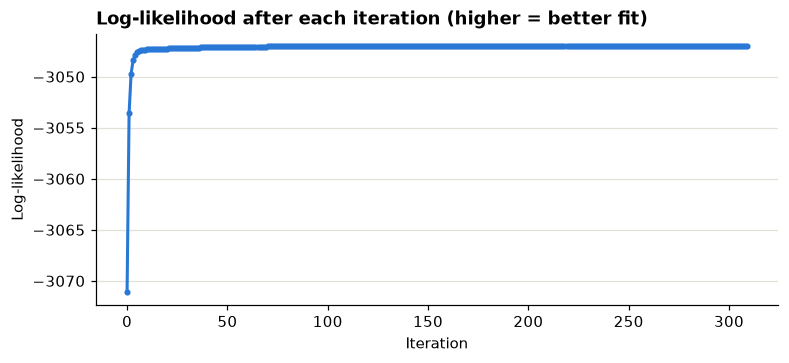

In [12]:
fig = plot_log_likelihood(table["Log-likelihood"].to_numpy())
fig.savefig("figures/em_2_log_likelihood.png", bbox_inches="tight")

The log-likelihood improves most during the first few iterations, then changes by smaller amounts. The model takes many iterations to converge with this start and tolerance. The overlap between the groups is one reason the estimates change gradually.

**How the fitted curves change:**

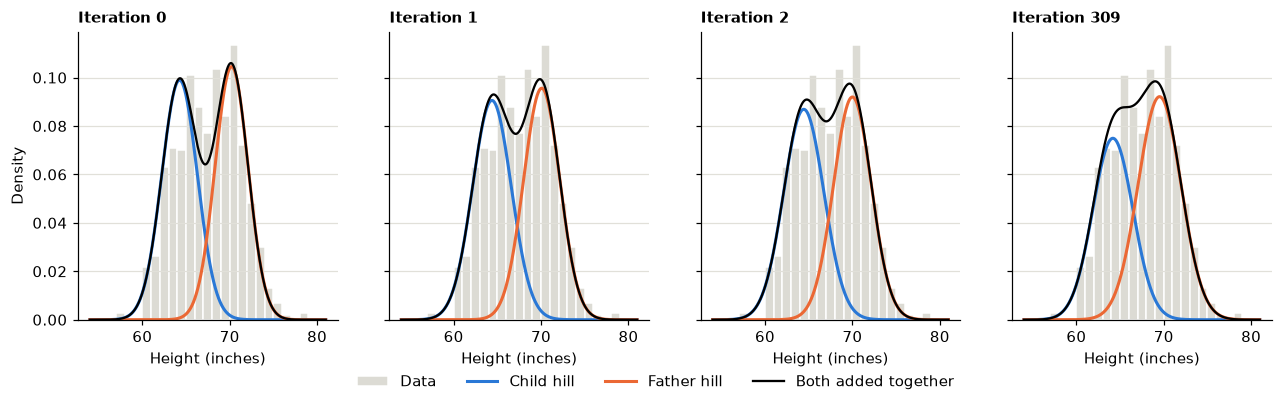

In [13]:
grid = np.arange(54, 81, 0.01)   # every height from 54 to 81 inches, in steps of 0.01

fig, axes = plt.subplots(1, 4, figsize=(14, 3.4), sharey=True)
for ax, i in zip(axes, [0, 1, 2, len(em_history) - 1]):
    c, f, ll = em_history[i]
    plot_fit(ax, heights, grid, score(grid, c), score(grid, f), f"Iteration {i}")
axes[0].set_ylabel("Density")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", bbox_to_anchor=(0.5, 0), ncol=4)
fig.savefig("figures/em_3_hills_moving.png", bbox_inches="tight")

## Step 9 — Why not just draw a line at the global mean?

**Because:**
1. A height just above the cutoff is assigned completely to one side, and one just below it to the other. EM gives heights near the overlap a probability for each group.
2. In our fitted model, the probability is 50/50 at about 66.54 inches. The global mean is 67.21 inches. That 50/50 point depends on the groups' shares and spreads, so it does not have to equal the overall mean.
3. In this dataset, the naive split gives smaller variances than the summaries calculated using the real sex labels. The table shows the values.
4. The simple split makes one cut and stops. Starting from that split, EM updates the estimates; in this run, the log-likelihood rises from about −3071 to −3047.

The table compares the naive split (iteration 0) with the fitted model. For the actual rows, we use the real labels to calculate height summaries by sex, then compare them with the model assignments in Step 9. There are no mothers in this pile: the female group is daughters, and the male group is sons plus fathers.

In [14]:
actual_female = weighted_group(heights, (~is_male).astype(float))   # same function, 0/1 weights
actual_male = weighted_group(heights, is_male.astype(float))

pd.DataFrame({
    "Naive split: child": start_child, "Naive split: father": start_father,
    "EM: child": child, "EM: father": father,
    "Actual: daughters": actual_female, "Actual: sons + fathers": actual_male,
}).T

,mean,var,share
Naive split: child,64.2598,4.1428,0.5048
Naive split: father,70.2147,3.5711,0.4952
EM: child,64.1772,5.3024,0.4325
EM: father,69.5186,6.0410,0.5675
Actual: daughters,64.1040,5.5368,0.3977
Actual: sons + fathers,69.2586,6.9027,0.6023


Global-mean line: 67.21 in
EM's 50/50 line:  66.54 in
Log-likelihood: naive -3071.12  ->  EM -3046.99


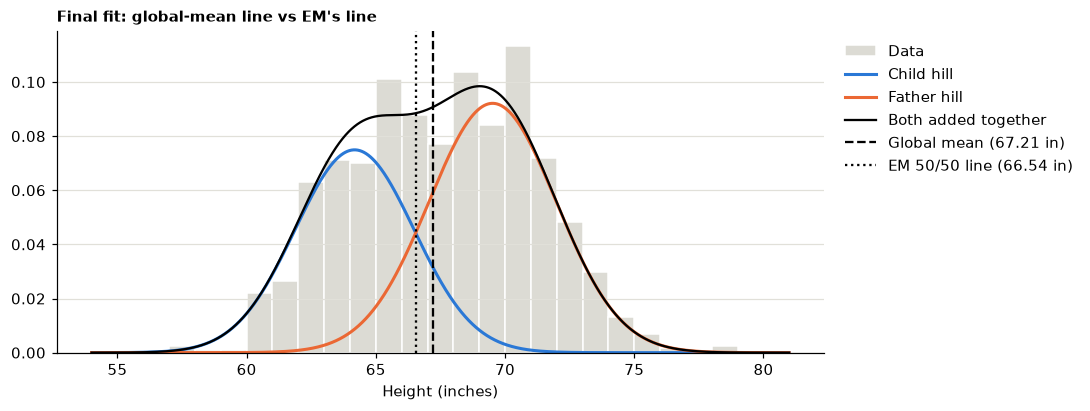

In [15]:
p_child_on_grid = e_step(grid, child, father)
boundary = grid[np.argmin(np.abs(p_child_on_grid - 0.5))]    # where it's 50/50

print(f"Global-mean line: {heights.mean():.2f} in")
print(f"EM's 50/50 line:  {boundary:.2f} in")
print(f"Log-likelihood: naive {em_history[0][2]:.2f}  ->  EM {final_score:.2f}")

fig, ax = plt.subplots(figsize=(9, 3.8))
plot_fit(ax, heights, grid, score(grid, child), score(grid, father), "Final fit: global-mean line vs EM's line",
               lines={f"Global mean ({heights.mean():.2f} in)": heights.mean(),
                      f"EM 50/50 line ({boundary:.2f} in)": boundary})
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
fig.savefig("figures/em_4_final_fit.png", bbox_inches="tight")

## Step 10 — Comparing the fitted groups with the real labels

We assign each height to the fitted group with the higher probability, then compare those assignments with the real labels.

In [16]:
em_says_child = e_step(heights, child, father) > 0.5

print(f"Child vs father: EM is right {np.mean(em_says_child == is_child):.1%} of the time")
print(f"(Always guessing 'child' would be right {np.mean(is_child):.1%} of the time)")
print(f"Female vs male:  EM is right {np.mean(em_says_child == ~is_male):.1%} of the time")

who = np.where(is_child, np.where(is_male, "Son", "Daughter"), "Father")
pd.crosstab(who, np.where(em_says_child, "EM says: Child", "EM says: Father"),
            rownames=["Real person"], colnames=[""])

Child vs father: EM is right 56.5% of the time
(Always guessing 'child' would be right 82.0% of the time)
Female vs male:  EM is right 84.7% of the time


,EM says: Child,EM says: Father
Real person,,
Daughter,392,61
Father,33,172
Son,80,401


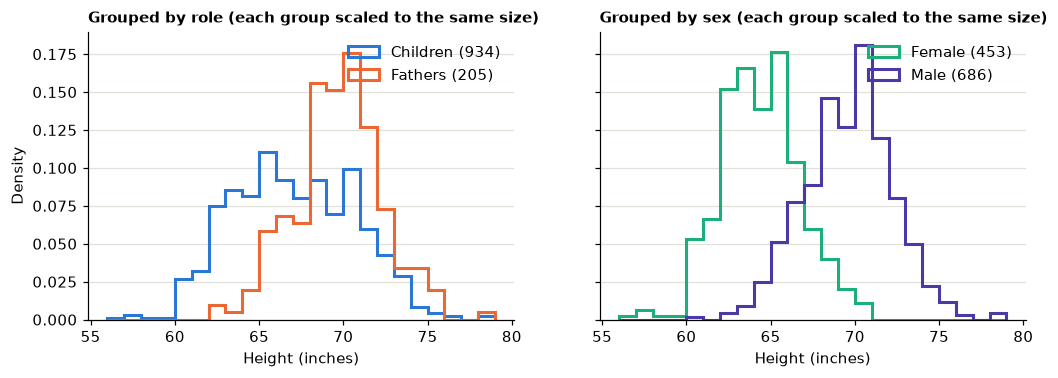

In [17]:
fig = plot_true_groups(heights, is_child, is_male)
fig.savefig("figures/em_5_true_groups.png", bbox_inches="tight")

**EM does not use the sex or family-role labels while fitting.** After fitting, we compared its assignments with the real labels. In this run, the two groups matched sex better than parent versus child. Galton's children are adults, so sons have heights close to fathers, while daughters are shorter. The plots compare the groups by role and by sex.

This result depends on the data and the starting values. It shows that, for this run, height alone did not reliably separate fathers from their adult children.

## Step 11 — Live demo (classify any height)

The probability for one new height is just the E-step on that one height.

,P(Child),P(Father)
Height (in),,
60,0.9965,0.0035
62,0.9825,0.0175
64,0.9098,0.0902
66,0.6236,0.3764
67,0.3934,0.6066
68,0.1988,0.8012
70,0.0328,0.9672
72,0.0042,0.9958
76,0.0000,1.0000


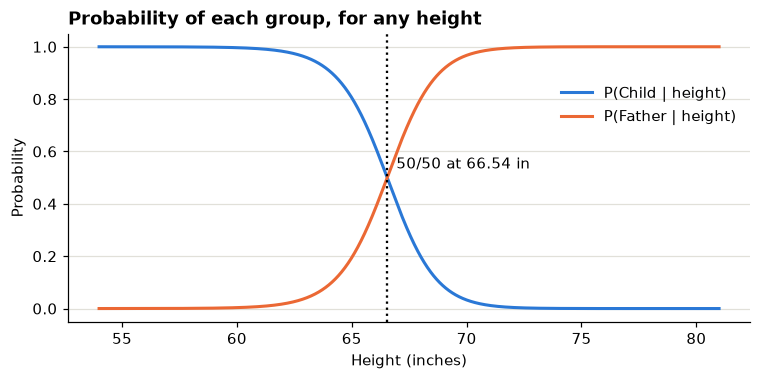

In [18]:
fig = plot_child_probability(grid, p_child_on_grid, boundary)
fig.savefig("figures/em_6_child_probability.png", bbox_inches="tight")

examples = np.array([60, 62, 64, 66, 67, 68, 70, 72, 76])
pd.DataFrame({"P(Child)": e_step(examples, child, father),
              "P(Father)": 1 - e_step(examples, child, father)},
             index=pd.Index(examples, name="Height (in)"))

In [19]:
def classify(height, unit="in"):
    """Print P(Child) and P(Father) for one height."""
    if unit == "cm":
        height = height / 2.54                # convert cm to inches
    p_child = e_step(height, child, father)
    print(f"Height: {height:.2f} inches")
    print(f"  P(Child  | height) = {p_child:.4f}")
    print(f"  P(Father | height) = {1 - p_child:.4f}")
    print("  Most likely:", "Child" if p_child > 0.5 else "Father")

**Enter the coach's height below and run the cell** (use `unit="cm"` for centimetres). The printed probabilities are for the model's shorter and taller fitted groups, labelled Child and Father here. They do not reliably establish the person's actual family role for this dataset.

In [20]:
classify(68, unit="in")

Height: 68.00 inches
  P(Child  | height) = 0.1988
  P(Father | height) = 0.8012
  Most likely: Father


## Summary

- **E-step:** calculate each height's probability for each fitted group.
- **M-step:** recalculate the groups' means, variances, and shares using those probabilities as weights.
- **Stopping:** stop when the log-likelihood improvement is below 0.000001.
- **Global-mean split:** it assigns each height to one side of a cutoff. Its estimates differ from the EM estimates in this dataset.
- **Checking the result:** compare the fitted groups with the real labels afterward. In this run, they matched sex more closely than family role.

# 2. Bayesian Probability: Which Words Predict a Negative IMDb Review?

We use the IMDb dataset of 50,000 movie reviews (each labelled positive or negative). The conditional probability we chose is **P(Negative | keyword)**.

## Step 1 — Bayes' theorem

We computed P(Negative | keyword) for each keyword, using Bayes' Theorem:

$$P(\text{Negative} \mid \text{keyword}) = \frac{P(\text{keyword} \mid \text{Negative})\, P(\text{Negative})}{P(\text{keyword})}$$

Each probability is a count divided by a count:

| Probability | How we count it |
|---|---|
| Prior P(Negative) | negative reviews ÷ all reviews |
| Likelihood P(keyword \| Negative) | negative reviews containing the keyword ÷ negative reviews |
| Marginal P(keyword) | reviews containing the keyword ÷ all reviews |
| Posterior P(Negative \| keyword) | likelihood × prior ÷ marginal |

## Step 2 — Load and clean the reviews

Basic Python only: `csv` to read the file and `re` to split text into words. Each review becomes a **set** of words, so a review counts once even if it repeats a word.

In [21]:
import csv
import re

DATA_PATH = "IMDB Dataset.csv"

In [22]:
def load_data(path):
    """Read the IMDB CSV and return a list of (review_text, sentiment) tuples."""
    data = []
    with open(path, encoding="utf-8", newline="") as f:
        reader = csv.reader(f)
        next(reader)                          # skip the header row
        for row in reader:
            data.append((row[0], row[1]))     # (review_text, sentiment)
    return data


In [23]:
def tokenize(text):
    """Lowercase the text, strip <br /> tags, and return the set of unique words."""
    text = text.lower()                       # 1. lowercase first
    text = text.replace("<br />", " ")        # 2. remove <br /> tags (space, not empty)
    words = re.findall(r"[a-z']+", text)      # 3. grab runs of letters/apostrophes
    words = [w.strip("'") for w in words]     # 4. remove quote marks from the ends
    return set(w for w in words if w)

In [24]:
def prepare(data):
    """Tokenize every review once and return a list of (set_of_words, sentiment) tuples."""
    return [(tokenize(text), sentiment) for text, sentiment in data]


In [25]:
prepared = prepare(load_data(DATA_PATH))
len(prepared)

50000

## Step 3 — Compute the four probabilities

One pass over the reviews counts the negative reviews, the reviews containing the keyword, and the reviews that are both. The `assert` checks Bayes' result against the direct count: (negative reviews with the keyword) ÷ (reviews with the keyword).

In [26]:
def compute_posterior(prepared, keyword):
    """Return (prior, likelihood, marginal, posterior) for P(Negative | keyword)."""
    total = len(prepared)
    negative = 0          # reviews labelled "negative"
    with_keyword = 0      # reviews containing the keyword
    both = 0              # negative AND containing the keyword

    for words, sentiment in prepared:
        is_neg = sentiment == "negative"
        has_kw = keyword in words
        if is_neg:
            negative += 1
        if has_kw:
            with_keyword += 1
        if is_neg and has_kw:
            both += 1

    prior = negative / total
    likelihood = both / negative if negative > 0 else 0
    marginal = with_keyword / total if total > 0 else 0
    posterior = likelihood * prior / marginal if marginal > 0 else None

    if posterior is not None:
        assert abs(posterior - both / with_keyword) < 1e-9

    return prior, likelihood, marginal, posterior, with_keyword

## Step 4 — Keywords and results

We chose words that appear in enough reviews to give reliable estimates (the rarest, "waste", appears in 2,533 reviews) and that people use to express a clear feeling about a film.

| Keyword | Expected signal | Why we chose it |
|---|---|---|
| great | positive | The most common praise word, but it also appears as "not great", so we expected it to be the weakest positive signal |
| excellent | positive | Strong praise that is rarely used sarcastically |
| wonderful | positive | Describes an enjoyable experience |
| perfect | positive | A superlative for cast, story or ending |
| worst | negative | A superlative used almost only to criticise ("worst movie I've seen") |
| awful | negative | A strong negative adjective |
| terrible | negative | A strong negative adjective |
| waste | negative | Appears in "waste of time / money", a typical complaint |

In [27]:
def print_results_table(prepared, keyword_groups):
    """Print one row per keyword for P(Negative | keyword)."""
    print(f"{'keyword':<12}{'type':<10}{'P(Neg)':>9}{'P(kw|Neg)':>11}{'P(kw)':>9}{'P(Neg|kw)':>11}{'reviews':>9}")
    for label, words in keyword_groups:
        for kw in words:
            prior, likelihood, marginal, posterior, with_keyword = compute_posterior(prepared, kw)
            if posterior is None:
                print(f"{kw:<12}{label:<10}never appears in the dataset")
                continue
            print(f"{kw:<12}{label:<10}{prior:>9.4f}{likelihood:>11.4f}{marginal:>9.4f}{posterior:>11.4f}{with_keyword:>9}")

In [28]:
POSITIVE_KEYWORDS = ["great", "excellent", "wonderful", "perfect"]
NEGATIVE_KEYWORDS = ["worst", "awful", "terrible", "waste"]

print_results_table(prepared, [("positive", POSITIVE_KEYWORDS), ("negative", NEGATIVE_KEYWORDS)])

keyword     type         P(Neg)  P(kw|Neg)    P(kw)  P(Neg|kw)  reviews
great       positive     0.5000     0.1640   0.2515     0.3259    12576
excellent   positive     0.5000     0.0274   0.0710     0.1926     3552
wonderful   positive     0.5000     0.0209   0.0556     0.1879     2778
perfect     positive     0.5000     0.0250   0.0533     0.2343     2667
worst       negative     0.5000     0.1609   0.0887     0.9073     4434
awful       negative     0.5000     0.1040   0.0576     0.9018     2882
terrible    negative     0.5000     0.0927   0.0540     0.8585     2699
waste       negative     0.5000     0.0944   0.0507     0.9313     2533


## Step 5 — Interpretation

### How to read the results

- Negative keywords (worst, awful, terrible and waste) have a **high** posterior (0.8585 to 0.9313), so a review containing one of them is very likely to be negative.
- Positive keywords (great, excellent, wonderful and perfect) have a **low** posterior (0.1879 to 0.3259). This is expected: these words point toward positive reviews.

### Findings

The negative keywords are the strongest evidence. Their P(Negative | keyword) ranges from 0.8585 (terrible) to 0.9313 (waste), so about 93% of reviews containing "waste" are negative. Among the positive keywords, "wonderful" (0.1879) and "excellent" (0.1926) are the strongest: about 81% of reviews containing them are positive.

The weakest keyword is "great" (0.3259), the closest to 0.5. It appears in 16.4% of negative reviews, but also in about 33.9% of positive reviews, which pulls its posterior toward 0.5. This makes it the least informative word.

The likelihoods are small. Even "worst" appears in only about 16% of negative reviews, so 84% of negative reviews do not contain it. One keyword cannot classify a review on its own, which is why real spam filters combine many words.

### Why the prior matters

Take a disease test that catches 90% of true cases and falsely flags 5% of healthy people. Test 1,000 people:

| Prevalence | Have it | True positives | Don't have it | False positives | P(has it \| positive test) |
|---|---|---|---|---|---|
| 10% | 100 | 90 | 900 | 45 | 90 / 135 ≈ 66.7% |
| 1% | 10 | 9 | 990 | about 50 (49.5) | 9 / 58.5 ≈ 15.4% |

The test is identical in both rows. Only the prior changed, and the posterior fell from about 67% to about 15%. At low prevalence, the many healthy people produce more false alarms than the few sick people produce true hits.

In our data the prior is exactly 0.5, because the dataset is split 25,000 / 25,000. If it were 90% positive reviews, P(Negative) would be 0.10. With the same likelihoods, the posterior for "worst" would drop from 0.9073 to about 0.52. The word would be just as informative, but negative reviews would be so rare that many reviews containing "worst" would be positive.

### Limitation

"great" had the weakest result (0.3259), likely because the method ignores context such as negation ("not great") and sarcasm.

### Assumptions

- A review counts once no matter how many times the word appears (we check presence, not frequency).
- Words are matched whole, so "awfully" does not count as "awful".
- Each keyword is analysed alone, ignoring all other words in the review.

# 4. Gradient Descent in Code

Here we turn the Part 3 manual calculations into Python.

Model: **ŷ = m1·x1 + m2·x2 + b**, written with matrices as **ŷ = X·m + b**

- Initial m = [-1, 2], initial b = [1, 1], learning rate α = 0.01
- Data: x = ((1, 3), (4, 10)), y = (5, 6)
- Cost: Mean Squared Error, J(m, b) = (1/n) Σ (ŷ − y)²

## Step 1 — Data, starting values and prediction

In [29]:
import numpy as np

m = np.array([-1.0, 2.0])
b = np.array([1.0, 1.0])
a = 0.01
iterations = 3   # number of updates = number of group members (same as Part 3)

x = np.array([(1, 3), (4,10)])
y =np.array([5, 6])

def predict(X, m, b):
    y_hat = X@m + b
    return y_hat

predict(x,m,b)

array([ 6., 17.])

## Step 2 — Error and cost

In [30]:
def compute_error(y_hat, y):
    error = y_hat -y
    return error

errors = compute_error(predict(x,m,b), y)
print(errors)

[ 1. 11.]


In [31]:
def compute_cost(errors):
    cost = np.mean(errors ** 2)
    return cost

cost = compute_cost(errors)
print(cost)

61.0


## Step 3 — Gradient with the chain rule

Using the chain rule on J = (1/n) Σ (ŷ − y)², with ŷ = X·m + b:

- ∂J/∂m = (2/n) · Xᵀ · (ŷ − y)
- ∂J/∂b = (2/n) · Σ (ŷ − y)

The `2` comes from the derivative of the square, and `Xᵀ` (or `1` for b) comes from the derivative of ŷ.

In [32]:
def compute_gradient(X, error):
    n = len(X)
    dj_dm = 2/n * X.T @ error
    dj_db = 2/n *np.sum(error)

    return dj_dm, dj_db

dj_dm, dj_db = compute_gradient(x, errors)
print(dj_dm, dj_db)

[ 45. 113.] 12.0


## Step 4 — Update m and b

In [33]:
def update(m, b, dj_dm, dj_db, a):
    m_new = m - a*dj_dm

    b_new = b - a*dj_db

    return m_new,b_new

print(update(m,b,dj_dm, dj_db, a))

(array([-1.45,  0.87]), array([0.88, 0.88]))


## Step 5 — Derivatives with SciPy

`compute_derivative` accepts any equation (a Python function) and a point, and returns the derivative at that point using `scipy.differentiate.derivative`.
We use it on the cost equation to get ∂J/∂m1, ∂J/∂m2 and ∂J/∂b, and check them against our formula above.

In [34]:
from scipy.differentiate import derivative

def compute_derivative(equation, point):
    return derivative(np.vectorize(equation), point).df

print("d/dt of t^2 at t = 3:", compute_derivative(lambda t: t**2, 3.0))

def cost_equation(m, b):
    return compute_cost(compute_error(predict(x, m, b), y))

def scipy_gradient(m, b):
    dj_dm1 = compute_derivative(lambda t: cost_equation(np.array([t, m[1]]), b), m[0])
    dj_dm2 = compute_derivative(lambda t: cost_equation(np.array([m[0], t]), b), m[1])
    dj_db = compute_derivative(lambda t: cost_equation(m, b + t), 0.0)
    return np.array([dj_dm1, dj_dm2]), dj_db

print("scipy:", scipy_gradient(m, b))
print("ours: ", compute_gradient(x, errors))

d/dt of t^2 at t = 3: 5.999999999999972
scipy: (array([ 45., 113.]), np.float64(11.999999999999773))
ours:  (array([ 45., 113.]), np.float64(12.0))


## Step 6 — Gradient descent loop

Each iteration: predict ŷ → compute error → compute gradient → update m and b → compute the new cost.
Every step is printed so it can be compared with our Part 3 manual calculations.

In [35]:
def gradient_descent(m, b, a, iterations, show_steps):
    history = [(m[0], m[1], b[0], cost_equation(m, b))]

    for i in range(1, iterations + 1):
        y_hat = predict(x, m, b)
        errors = compute_error(y_hat, y)
        dj_dm, dj_db = compute_gradient(x, errors)
        scipy_dm, scipy_db = scipy_gradient(m, b)
        m, b = update(m, b, dj_dm, dj_db, a)
        cost = cost_equation(m, b)
        history.append((m[0], m[1], b[0], cost))

        if show_steps:
            print(f"--- iteration {i} ---")
            print("y_hat:", y_hat)
            print("error:", errors)
            print("dJ/dm:", dj_dm, "  scipy:", scipy_dm)
            print("dJ/db:", dj_db, "  scipy:", scipy_db)
            print("new m:", m, "  new b:", b)
            print("cost: ", cost)

    return m, b, np.array(history)

m_final, b_final, history = gradient_descent(m, b, a, iterations, show_steps=True)

--- iteration 1 ---
y_hat: [ 6. 17.]
error: [ 1. 11.]
dJ/dm: [ 45. 113.]   scipy: [ 45. 113.]
dJ/db: 12.0   scipy: 11.999999999999773
new m: [-1.45  0.87]   new b: [0.88 0.88]
cost:  6.845000000000002
--- iteration 2 ---
y_hat: [2.04 3.78]
error: [-2.96 -2.22]
dJ/dm: [-11.84 -31.08]   scipy: [-11.84 -31.08]
dJ/db: -5.1800000000000015   scipy: -5.180000000000035
new m: [-1.3316  1.1808]   new b: [0.9318 0.9318]
cost:  2.72381716
--- iteration 3 ---
y_hat: [3.1426 7.4134]
error: [-1.8574  1.4134]
dJ/dm: [3.7962 8.5618]   scipy: [3.7962 8.5618]
dJ/db: -0.4439999999999995   scipy: -0.4440000000000097
new m: [-1.369562  1.095182]   new b: [0.93624 0.93624]
cost:  2.3904438107600003


## Step 7 — Predictions with the final m and b

In [36]:
print("final m:", m_final, "  final b:", b_final)
print("predictions:", predict(x, m_final, b_final), "  real y:", y)

m_long, b_long, long_history = gradient_descent(m, b, a, 2000, show_steps=False)
print("\nafter 2000 iterations")
print("final m:", m_long, "  final b:", b_long)
print("predictions:", predict(x, m_long, b_long), "  real y:", y)

final m: [-1.369562  1.095182]   final b: [0.93624 0.93624]
predictions: [2.852224 6.409812]   real y: [5 6]



after 2000 iterations
final m: [-2.22575528  1.09677519]   final b: [3.93530626 3.93530626]
predictions: [4.99987656 6.00003708]   real y: [5 6]


## Step 8 — Plots

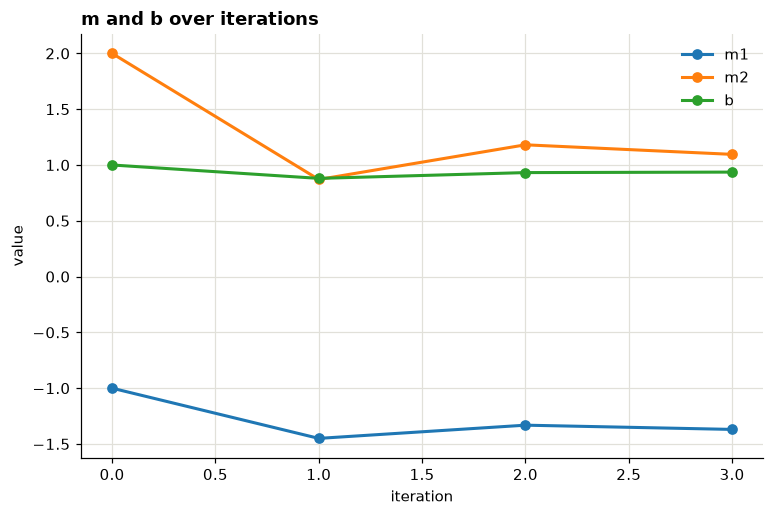

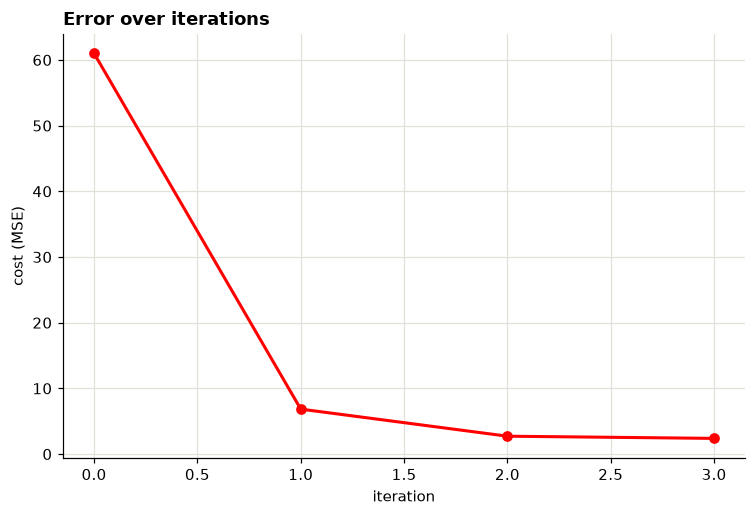

In [37]:
import matplotlib.pyplot as plt

def plot_parameters(history, title, filename):
    marker = "o" if len(history) <= 20 else None
    plt.figure(figsize=(8, 5))
    plt.plot(history[:, 0], marker=marker, label="m1")
    plt.plot(history[:, 1], marker=marker, label="m2")
    plt.plot(history[:, 2], marker=marker, label="b")
    plt.xlabel("iteration")
    plt.ylabel("value")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.savefig(filename)
    plt.show()

def plot_cost(history, title, filename):
    marker = "o" if len(history) <= 20 else None
    plt.figure(figsize=(8, 5))
    plt.plot(history[:, 3], marker=marker, color="red")
    plt.xlabel("iteration")
    plt.ylabel("cost (MSE)")
    plt.title(title)
    plt.grid(True)
    plt.savefig(filename)
    plt.show()

plot_parameters(history, "m and b over iterations", "figures/gd_1_m_and_b.png")
plot_cost(history, "Error over iterations", "figures/gd_2_error.png")

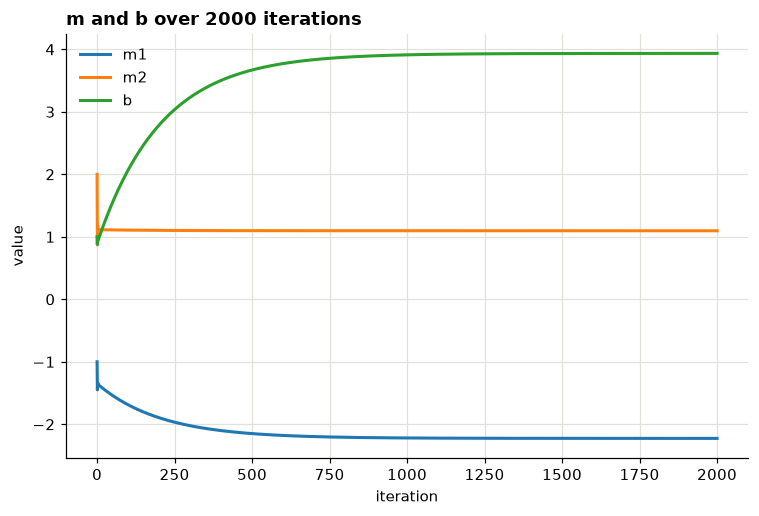

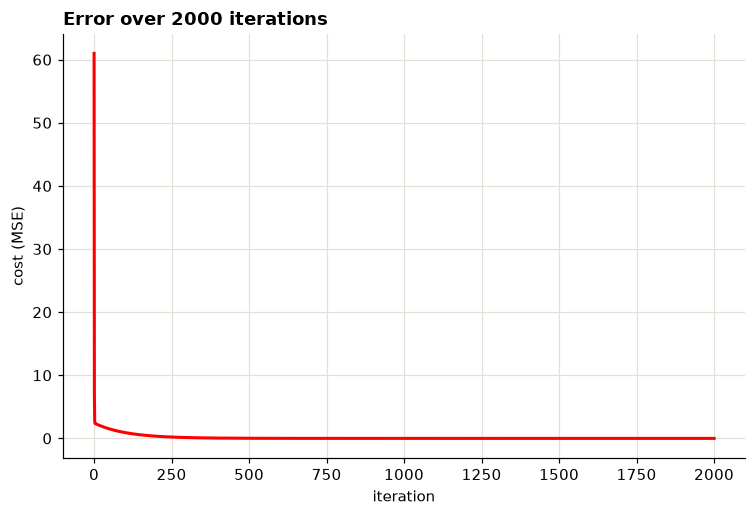

In [38]:
plot_parameters(long_history, "m and b over 2000 iterations", "figures/gd_3_m_and_b_long.png")
plot_cost(long_history, "Error over 2000 iterations", "figures/gd_4_error_long.png")

## Step 9 — What we observe

- The cost drops from **61** to **6.845** after the first update, then to **2.72** and **2.39**, so every update reduces the error.
- The first update is a big jump (m2 goes from 2 to 0.87) because the starting error for the second point (11) is large and x2 = 10 makes ∂J/∂m2 = 113 big. After that, m and b move in smaller steps.
- m2 overshoots, then settles. b dips to 0.88 on the first update, then rises slowly because the predictions are now below the real y values, which pushes the line up.
- If we keep going for 2000 iterations, the cost goes to almost 0. With 3 parameters and only 2 points, the line can pass exactly through both points, giving predictions ≈ (5, 6).
- SciPy's numerical derivatives match our chain rule formulas at every step, which confirms our Part 3 derivation.